# Real Estate Housing Price Prediction (OLS, Ridge & Lasso)
**Task 2 – Datheon AI Internship**

Predict `median_house_value` on the California Housing dataset. Steps: missing-value imputation, correlation analysis, interaction feature engineering, multicollinearity handling (VIF), encoding + standardization, and comparison of **OLS vs Ridge (L2) vs Lasso (L1)** using RMSE, MAE and R². Ridge/Lasso hyperparameters tuned with `GridSearchCV`.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load the Dataset

In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nocean_proximity counts:\n", df["ocean_proximity"].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values:
 total_bedrooms    207
dtype: int64

ocean_proximity counts:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 3. Exploratory Analysis
### 3.1 Target distribution

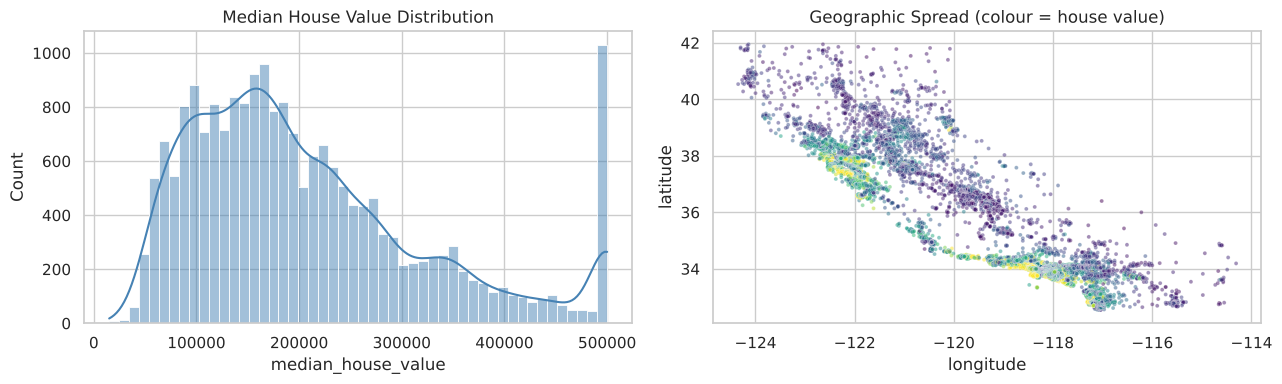

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=50, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Median House Value Distribution")
sns.scatterplot(data=df, x="longitude", y="latitude", hue="median_house_value",
                palette="viridis", s=8, alpha=0.5, ax=ax[1], legend=False)
ax[1].set_title("Geographic Spread (colour = house value)")
plt.tight_layout(); plt.show()

### 3.2 Correlation heatmap (raw numeric features)
Null values are ignored pairwise by pandas, so this works before imputation.

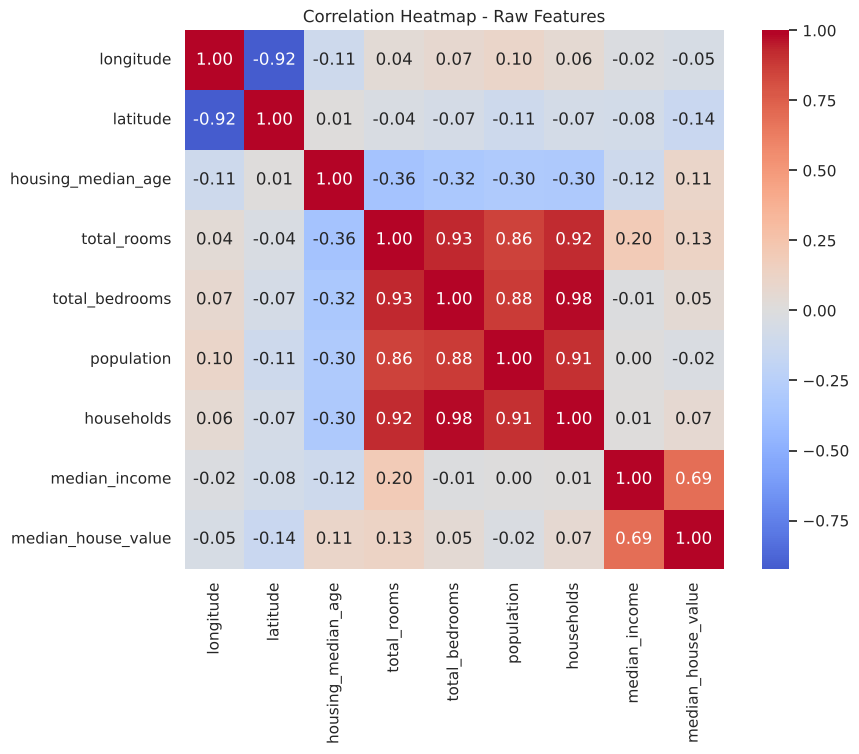

Correlation with target:
 median_house_value    1.000
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [5]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap - Raw Features")
plt.show()

print("Correlation with target:\n", corr["median_house_value"].sort_values(ascending=False).round(3))

**Observation:** `median_income` is the strongest predictor. `total_rooms`, `total_bedrooms`, `population` and `households` are very strongly correlated with each other (multicollinearity), which we handle in Section 5.

## 4. Feature Engineering (Interaction & Ratio Features)
Raw totals depend on block size, so per-household ratios are more meaningful. We also add an interaction term between income and rooms.

In [6]:
df_fe = df.copy()
df_fe["rooms_per_household"] = df_fe["total_rooms"] / df_fe["households"]
df_fe["bedrooms_per_room"] = df_fe["total_bedrooms"] / df_fe["total_rooms"]   # NaN where total_bedrooms is NaN
df_fe["population_per_household"] = df_fe["population"] / df_fe["households"]
df_fe["income_x_rooms"] = df_fe["median_income"] * df_fe["rooms_per_household"]   # interaction feature

df_fe[["rooms_per_household", "bedrooms_per_room", "population_per_household", "income_x_rooms"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
income_x_rooms,20640.0,22.550365,17.923133,0.856971,11.686844,18.021764,27.864426,612.966667


In [7]:
new_corr = df_fe.select_dtypes(include=np.number).corr()["median_house_value"].sort_values(ascending=False)
print(new_corr.round(3))

median_house_value          1.000
median_income               0.688
income_x_rooms              0.555
rooms_per_household         0.152
total_rooms                 0.134
housing_median_age          0.106
households                  0.066
total_bedrooms              0.050
population_per_household   -0.024
population                 -0.025
longitude                  -0.046
latitude                   -0.144
bedrooms_per_room          -0.256
Name: median_house_value, dtype: float64


## 5. Multicollinearity Check (VIF)
VIF > 10 indicates severe multicollinearity. We compute VIF on median-imputed numeric features, first for the raw set, then after replacing raw count columns with ratio features.

In [8]:
def compute_vif(frame):
    frame = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(frame), columns=frame.columns)
    vifs = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        vifs[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vifs, name="VIF").sort_values(ascending=False).round(2)

raw_feats = ["longitude", "latitude", "housing_median_age", "total_rooms",
             "total_bedrooms", "population", "households", "median_income"]
print("VIF - RAW features:")
print(compute_vif(df_fe[raw_feats]))

VIF - RAW features:


households            28.28
total_bedrooms        26.88
total_rooms           12.13
latitude               8.83
longitude              8.70
population             6.26
median_income          1.69
housing_median_age     1.26
Name: VIF, dtype: float64


In [9]:
# Drop the highly collinear raw counts; keep their ratio versions instead
engineered_feats = ["longitude", "latitude", "housing_median_age", "median_income",
                    "rooms_per_household", "bedrooms_per_room", "population_per_household"]
print("VIF - AFTER replacing raw counts with ratios:")
print(compute_vif(df_fe[engineered_feats]))

VIF - AFTER replacing raw counts with ratios:
latitude                    9.16
longitude                   8.87
median_income               1.96
bedrooms_per_room           1.86
rooms_per_household         1.31
housing_median_age          1.11
population_per_household    1.00
Name: VIF, dtype: float64


**Handling multicollinearity:**
1. Replaced `total_rooms`, `total_bedrooms`, `population`, `households` with ratio features → large VIF drop on those columns.
2. `longitude` and `latitude` stay correlated with each other (they jointly encode location and are important predictors), so we rely on **Ridge/Lasso regularization**, which is specifically designed to stabilize coefficients under correlated features.

## 6. Train / Test Split & Preprocessing Pipeline
Split **before** imputation/scaling so test data never leaks into the preprocessing statistics.

In [10]:
num_features = ["longitude", "latitude", "housing_median_age", "median_income",
                "rooms_per_household", "bedrooms_per_room",
                "population_per_household", "income_x_rooms"]
cat_features = ["ocean_proximity"]

X = df_fe[num_features + cat_features]
y = df_fe["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

Train: (16512, 9) | Test: (4128, 9)


## 7. Model Training
### 7.1 OLS (baseline)

In [11]:
ols = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
ols.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',..., 'population_per_household','income_x_rooms','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed 

### 7.2 Ridge (L2) with GridSearchCV

In [12]:
ridge_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Ridge())]),
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 50, 100, 500, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X_train, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best CV RMSE   :", round(-ridge_grid.best_score_, 2))

Best Ridge alpha: 1
Best CV RMSE   : 70418.79


### 7.3 Lasso (L1) with GridSearchCV

In [13]:
lasso_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Lasso(max_iter=20000))]),
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 50, 100, 500, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X_train, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])
print("Best CV RMSE   :", round(-lasso_grid.best_score_, 2))

Best Lasso alpha: 1
Best CV RMSE   : 70419.75


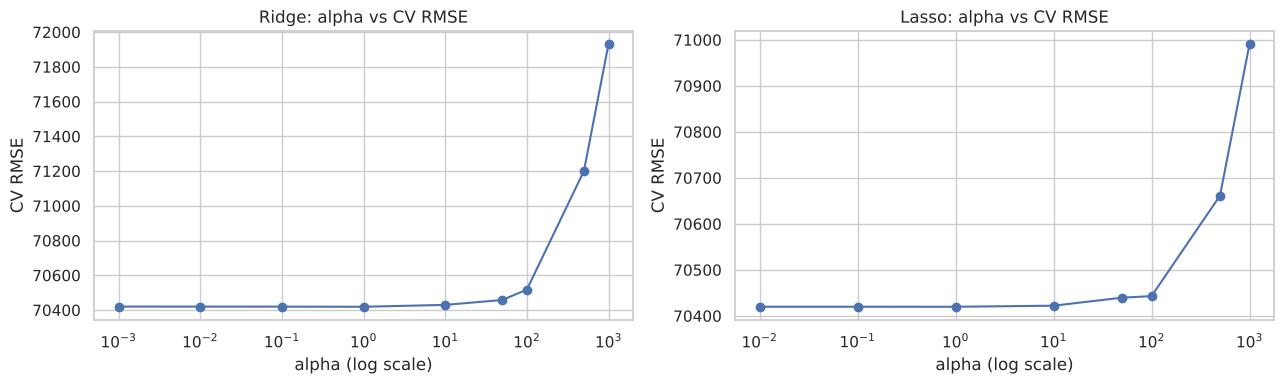

In [14]:
# Alpha vs CV RMSE curves
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, grid, name in [(ax[0], ridge_grid, "Ridge"), (ax[1], lasso_grid, "Lasso")]:
    res = pd.DataFrame(grid.cv_results_)
    a.semilogx(res["param_model__alpha"].astype(float), -res["mean_test_score"], marker="o")
    a.set_title(f"{name}: alpha vs CV RMSE")
    a.set_xlabel("alpha (log scale)"); a.set_ylabel("CV RMSE")
plt.tight_layout(); plt.show()

## 8. Model Comparison (RMSE, MAE, R²)

In [15]:
models = {
    "OLS": ols,
    "Ridge (L2)": ridge_grid.best_estimator_,
    "Lasso (L1)": lasso_grid.best_estimator_,
}

rows, preds = [], {}
for name, model in models.items():
    p = model.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R2": r2_score(y_test, p),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,RMSE,MAE,R2
Model,,,
OLS,71650.9183,51568.3513,0.6082
Ridge (L2),71658.3343,51574.7944,0.6081
Lasso (L1),71652.2139,51569.4045,0.6082


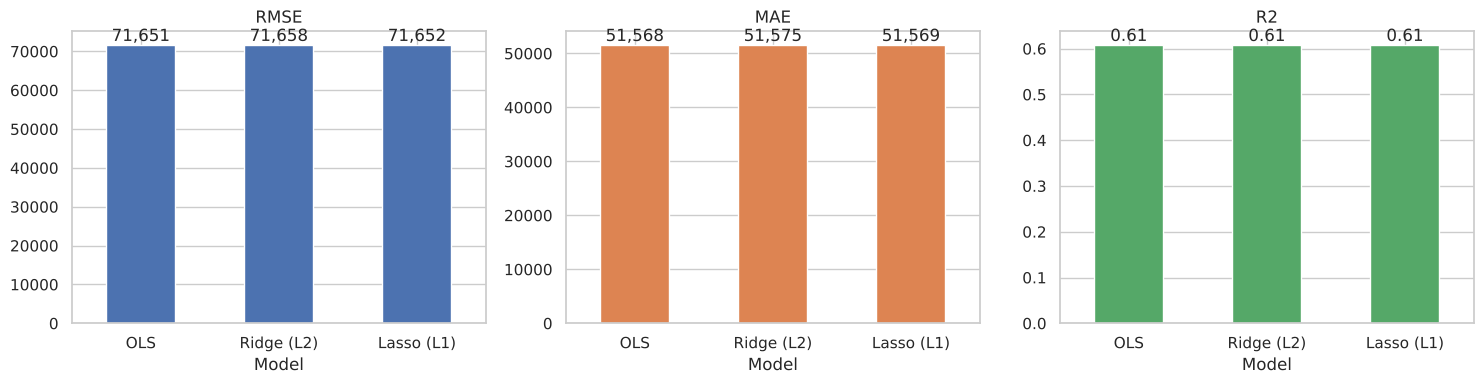

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, metric, color in zip(ax, ["RMSE", "MAE", "R2"], ["#4c72b0", "#dd8452", "#55a868"]):
    results[metric].plot(kind="bar", ax=a, color=color, rot=0)
    a.set_title(metric)
    for i, v in enumerate(results[metric]):
        a.text(i, v, f"{v:,.2f}" if metric == "R2" else f"{v:,.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 9. Coefficient Analysis (effect of L1 vs L2)

,OLS,Ridge,Lasso
longitude,-52302.1,-52264.0,-52288.9
latitude,-51208.4,-51177.4,-51195.8
housing_median_age,11448.3,11452.1,11448.2
median_income,101183.1,101082.7,101150.9
rooms_per_household,18068.4,18022.2,18050.9
bedrooms_per_room,21353.8,21344.0,21349.3
population_per_household,-4271.1,-4269.8,-4269.7
income_x_rooms,-24009.9,-23896.4,-23971.9
ocean_proximity_<1H OCEAN,-23732.0,-18877.6,-3258.7
ocean_proximity_INLAND,-57720.3,-52887.7,-37257.5


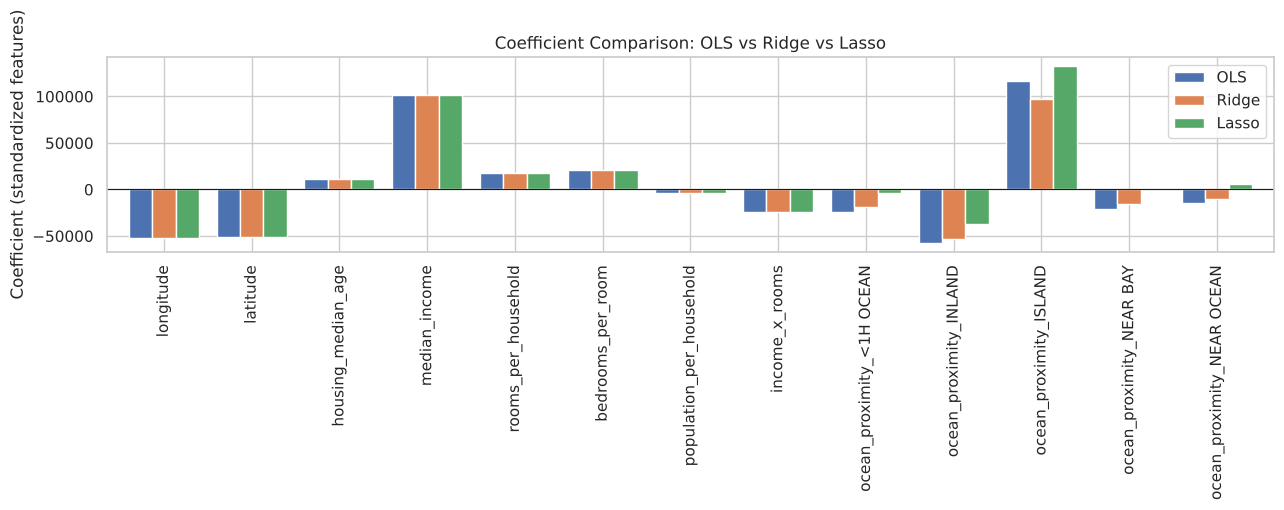

Features eliminated by Lasso: ['ocean_proximity_NEAR BAY']


In [17]:
feat_names = (num_features +
              list(ols.named_steps["prep"].named_transformers_["cat"]
                   .named_steps["onehot"].get_feature_names_out(cat_features)))

coef_df = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": ridge_grid.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_grid.best_estimator_.named_steps["model"].coef_,
}, index=feat_names).round(1)
display(coef_df)

coef_df.plot(kind="bar", figsize=(13, 5), width=0.8)
plt.title("Coefficient Comparison: OLS vs Ridge vs Lasso")
plt.ylabel("Coefficient (standardized features)")
plt.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

zeroed = coef_df.index[coef_df["Lasso"] == 0].tolist()
print("Features eliminated by Lasso:", zeroed if zeroed else "None")

## 10. Predicted vs Actual

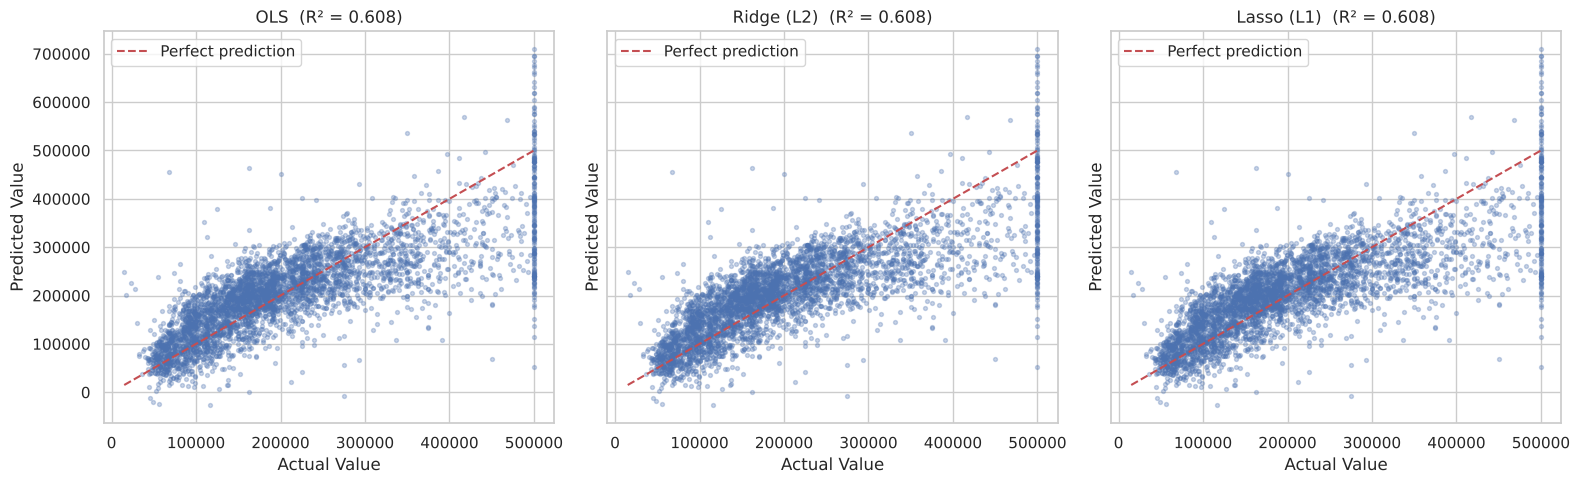

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, alpha=0.3, s=8)
    a.plot(lims, lims, "r--", lw=1.5, label="Perfect prediction")
    a.set_title(f"{name}  (R² = {r2_score(y_test, p):.3f})")
    a.set_xlabel("Actual Value"); a.set_ylabel("Predicted Value"); a.legend()
plt.tight_layout(); plt.show()

## 11. Residual Error Analysis
### 11.1 Residual distribution

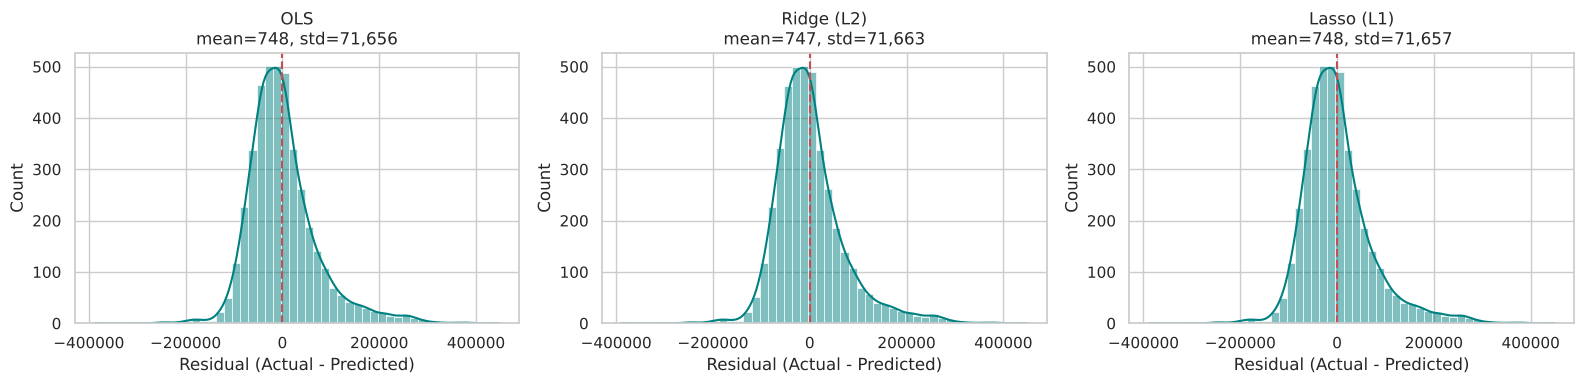

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for a, (name, p) in zip(ax, preds.items()):
    resid = y_test - p
    sns.histplot(resid, bins=50, kde=True, ax=a, color="teal")
    a.axvline(0, color="r", ls="--")
    a.set_title(f"{name}\nmean={resid.mean():,.0f}, std={resid.std():,.0f}")
    a.set_xlabel("Residual (Actual - Predicted)")
plt.tight_layout(); plt.show()

### 11.2 Residuals vs Predicted

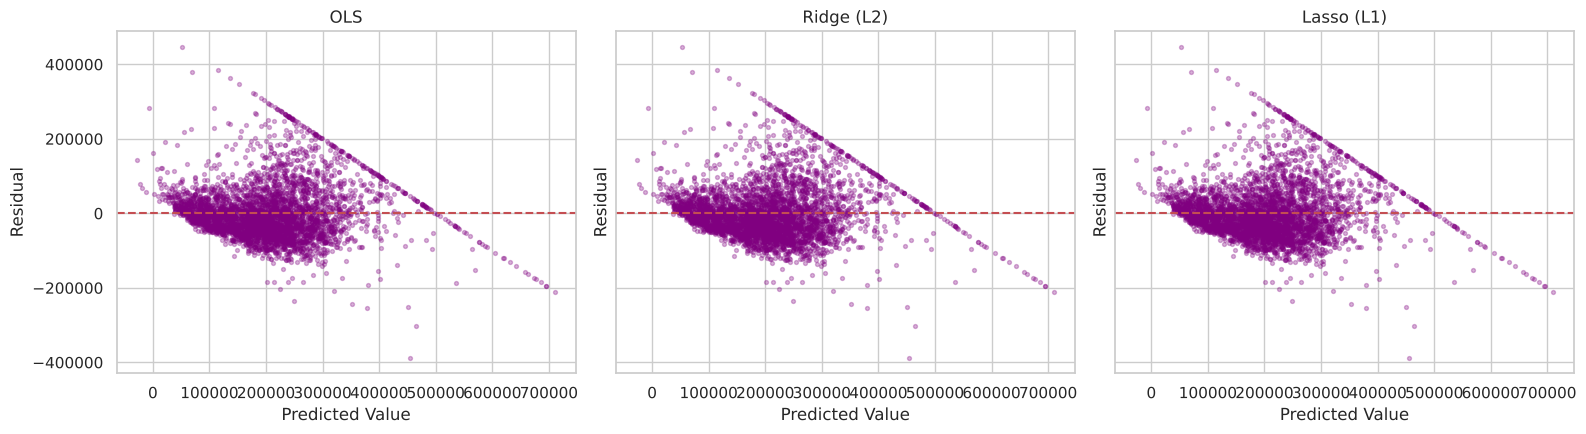

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(p, y_test - p, alpha=0.3, s=8, color="purple")
    a.axhline(0, color="r", ls="--")
    a.set_title(name)
    a.set_xlabel("Predicted Value"); a.set_ylabel("Residual")
plt.tight_layout(); plt.show()

## 12. Conclusion

In [21]:
best = results["RMSE"].idxmin()
print(f"Best model by RMSE: {best}")
print(results)

Best model by RMSE: OLS
                  RMSE         MAE      R2
Model                                     
OLS         71650.9183  51568.3513  0.6082
Ridge (L2)  71658.3343  51574.7944  0.6081
Lasso (L1)  71652.2139  51569.4045  0.6082


**Key takeaways**
- Missing `total_bedrooms` values (207 rows) were median-imputed inside the pipeline (fit on train only, so no leakage).
- Interaction/ratio features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`, `income_x_rooms`) captured structure that raw totals could not, and reduced multicollinearity.
- OLS, Ridge and Lasso perform very similarly because after VIF-based feature cleanup the model is not heavily over-parameterised; the benefit of regularization here is mainly coefficient stability rather than a big accuracy jump.
- Residual plots show a fan/ceiling pattern at the high end: the dataset caps `median_house_value` at $500,000, and linear models cannot capture that plus nonlinear location effects. Tree-based models or splines would be natural next steps.